# Unterrichtsbeispiel

[&larr; Einführung](01_DATENAUSWERTUNG.ipynb)

## Motivation

Wir wollen anhand eines praktischen Beispiels in die Thematik der Messauswertung einsteigen und uns dabei die relevanten Kenntnisse aneignen.

---

## Aufgabe

Im Folgenden wollen wir die Periodendauer eines Fadenpendels messen und das Ergebnis sinnvoll (inkl. Unsicherheit) angeben.

<figure style="text-align:center; margin:1em auto;">
    <img src="img/Fadenpendel.gif" width=50% />
    <figcaption style="font-size:0.9em; font-style:italic; margin-top:0.4em;">
        Fadenpendel
    </figcaption>
</figure>

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### a) Messung durchführen

Als erstes messen wir die Periodendauer $T$ der Pendelschwingung. Um ein repräsentatives Messergebnis inkl. Messunsicherheit bestimmen zu können, führen wir mehrere Messungen durch und achten darauf dass die Einzelmessungen möglichst unabhängig voneinander sind (also z. B. Pendel jeweils neu "einschwingen", verschiedene Auslenkungen messen, Messungen durch verschiedene Personen durchführen etc.).

- Pro Person 3 Messungen
- Pendel jeweils neu auslenken (nur einige Grad) und aus Ruhelage loslassen
- Messung erst nach ein paar Einschwingperioden starten


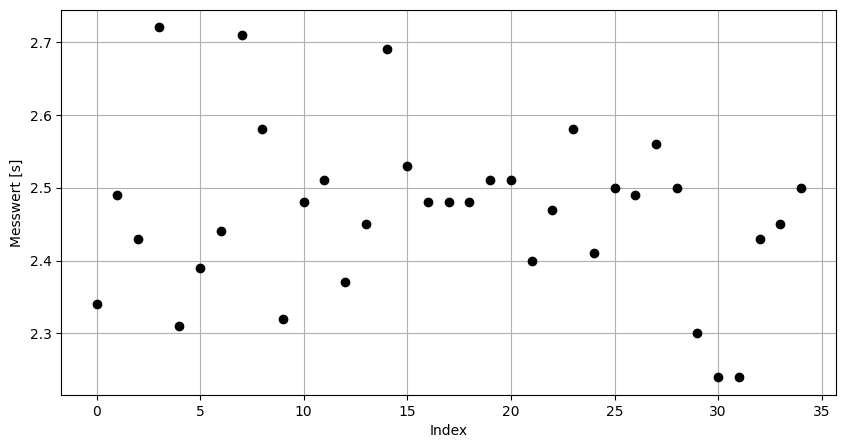

In [6]:
T_mess = [2.34, 2.49, 2.43, 2.72, 2.31, 2.39, 2.44, 2.71, 2.58, 2.32,
         2.48, 2.51, 2.37, 2.45, 2.69, 2.53, 2.48, 2.48, 2.48, 2.51, 2.51,
         2.40, 2.47, 2.58, 2.41, 2.50, 2.49, 2.56, 2.50, 2.30, 2.24, 2.24,
         2.43, 2.45, 2.50]
T_mess = np.array(T_mess)
N = len(T_mess)

# Punktwolke
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(T_mess, 'ko')
ax.set_xlabel('Index')
ax.set_ylabel('Messwert [s]')
ax.grid()
plt.show()

Zur Visualisierung der Verteilung bietet sich das Histogramm an.

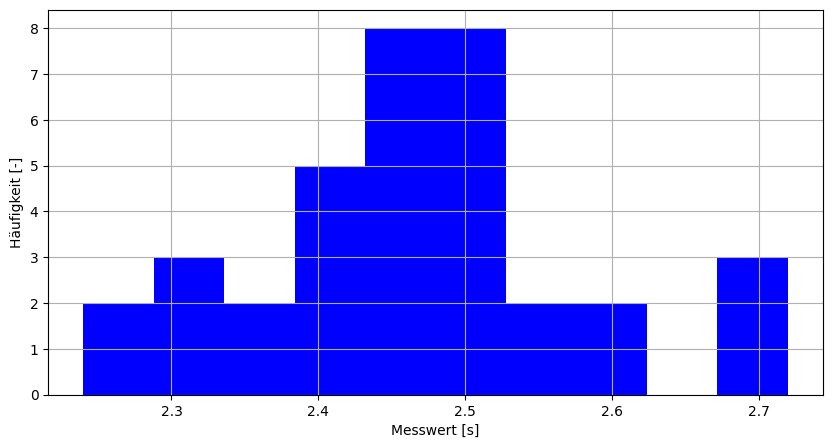

In [42]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(T_mess, color='b')
ax.set_xlabel('Messwert [s]')
ax.set_ylabel('Häufigkeit [-]')
ax.grid()
plt.show()

### b) Messergebnis bestimmen

Die beste Schätzung des "wahren" Wertes entspricht dem Mittelwert der Einzelmessungen.

- Zufällige Fehler werden dadurch eliminiert.
- Systematische Fehler werden nicht eliminiert, d. h. systematische Fehler müssen vorgängig möglichst korrigiert werden.

In [8]:
T = T_mess.mean()
print(T)

2.4654285714285717


Damit haben wir bereits unser Messergebnis der Periodendauer $T$ des Fadenpendels. Das ist allerdings noch nicht viel wert, denn:
- wir wissen nicht, wie sicher/unsicher dieses Ergebnis ist,
- wir wissen nicht, wie wir das Ergebnis sinnvoll runden sollen.

In [9]:
s = T_mess.std(ddof=1)
print(s)

0.11400058970804278


Nun wollen wir die Messunsicherheit der Periodendauer bestimmen. Diese setzt sich i. Allg. zusammen aus Anteilen aus der statistischen Analyse ("Streuung der Einzelmessungen") und Anteilen, die z. B. aus einem Datenblatt eines Messgerätes o. ä. kommen.

### c) Unsicherheit aus statistischer Analyse bestimmen

Wird die Standardunsicherheit aus einer Messreihe von $N$ Einzelmessungen bestimmt, so entspricht sie der Standardabweichung des Mittelwertes und wird mit $s/\sqrt{N}$ berechnet. $s$ ist dabei die Standardabweichung der Messreihe und kann mit der Array-Methode `.std(ddof=1)` berechnet werden.

In [19]:
u_T_1 = s / np.sqrt(N)
print(u_T_1)

0.01926961668666246


### d) Unsicherheit aus anderen Quellen (Erfahrung, Datenblätter, Kalibrierprotokollen)

Aufgrund der menschlichen Reaktionszeit etc. tritt eine zusätzliche Unsicherheit $u_2$ auf, die wir hier grob abschätzen. In industriellen Messungen wären hier Unsicherheiten von Messgeräten (aus Datenblättern/Kalibrierprotokollen, Unsicherheiten durch endliche Auflösung etc.) aufgeführt.

In [20]:
u_T_2 = 0.01

### e) Messunsicherheitsbeiträge addieren

Mehrere Unsicherheitsbeiträge werden quadratisch addiert. Wichtig ist, dass sämtliche Unsicherheitsbeiträge auf demselben Vertrauensniveau vorliegen (1 Sigma- bzw. 68.3%-Niveau).

In [21]:
u_T = np.sqrt(u_T_1**2 + u_T_2**2)
print(u_T)

0.021709862442007784


### f) Erweiterte Messunsicherheit

Bei der finalen Angabe des Ergebnis wird die Unsicherheit typischerweise auf dem 95%-Vertrauensniveau angegeben, d. h. wir müssen die oben berechnete Unsicherheit (diese ist auf dem 68.3%-Vertrauensniveau) mit einem Erweiterungsfaktor $k = 2$ multiplizieren, um die erweiterte Messunsicherheit zu erhalten.

In [22]:
k = 2 # Erweiterungsfaktor (95%)
U_T = k * u_T
print(U_T)

0.04341972488401557


### g) Ergebnis ausgeben

Das Endergebnis wird typischerweise in der Form $T = \ldots \pm \ldots \text{s} \quad (k = 2)$ angegeben, wobei die Messunsicherheit auf zwei signifikante Stellen zu runden ist und die Messgrösse auf dieselbe Stellenanzahl (Faustregel). Zu beachten ist, dass zur Unsicherheit immer der Erweiterungsfaktor (oder alternativ das Vertrauensniveau) angegeben werden muss.

In [23]:
print(f'T = {T:.3f} +/- {U_T:.3f} s (k = {k})')

T = 2.465 +/- 0.043 s (k = 2)


### h) Zusatz: Erdbeschleungiung bestimmen

Für ein ideales Pendel hängt die Periodendauer für kleine Auslenkungen gemäss folgender Formel mit der Fadenlänge $L$ und Erdbeschleunigung $g$ zusammen. Form und Masse des Körpers sowie des Fadens, Reibung etc. werden nicht berücksichtigt und darum spricht man vom idealen/mathematischen Pendel. 

$$ T_{\text{ideal}} = 2 \pi \sqrt{\frac{L}{g}} $$

Umgestellt nach $g$ ergibt sich:

$$ g = 4 \pi^2 \cdot \frac{L}{T_{\text{ideal}}^2}$$

Die Erdbeschleunigung $g$ ist also eine Funktion der Periodendauer $T$ und der Fadenlänge $L$. Wir können also aus unserer Periodendauermessung die Erdbeschleunigung bestimmen, wenn wir noch die Fadenlänge (vom Drehpunkt bis zum Kugelschwerpunkt) messen. 

In [37]:
L = 1.546  # gemessene Fadenlänge [m]

g = 4*np.pi**2*L/T**2  # Berechnung der Erdbeschleunigung
print(g)

10.041171321254733


Natürlich hat auch die Fadenlänge eine Messunsicherheit. Diese schätzen wir hier sinnvoll ab.

In [38]:
u_L = 0.001  # geschätzte Unsicherheit der Fadenlänge [m]

Die Messunsicherheit der Ergebnisgrösse (Erdbeschleunigung) lässt sich anhand des Fehlerfortpflanzungsgesetzes bestimmen. Dafür braucht man die Ableitungen nach den einzelnen unabhängigen Variablen (hier $T$ und $L$) und diese werden mit den jeweiligen Messunsicherheiten multipliziert und quadratisch addiert.

$$ u_g = \sqrt{\left(\frac{dg}{dT}\cdot u_T\right)^2 + \left(\frac{dg}{dL}\cdot u_L\right)^2} $$

In [39]:
dg_dT = -8*np.pi**2*L/T**3  # Ableitung nach T
dg_dL = 4*np.pi**2/T**2  # Ableitung nach L

u_g = np.sqrt((dg_dT * u_T)**2 + (dg_dL * u_L)**2)

Die Berechnung erfolgte mit den Standardunsicherheiten (68.3%-Niveau), d. h. für die finale Angabe des Ergebnisses gehen wir wiederum auf das 95%-Niveau (k = 2).

In [40]:
U_g = k * u_g

print(f'g = {g:.2f} +/- {U_g:.2f} m/s^2 (k = {k})')

g = 10.04 +/- 0.35 m/s^2 (k = 2)


Wie immer ist auch hier eine Visualisierung hilfreich, wenn auch in diesem Fall nicht besonders interessant. Wir plotten hier letztlich nur das Messergebnis mit der Messunsicherheit. Matplotplit bietet für das Plotten von Fehlerbalken den Plottyp `errorbar(x, y, yerr, ...)`, wobei mit `yerr` die Grösse der Fehlerbalken definiert werden können.

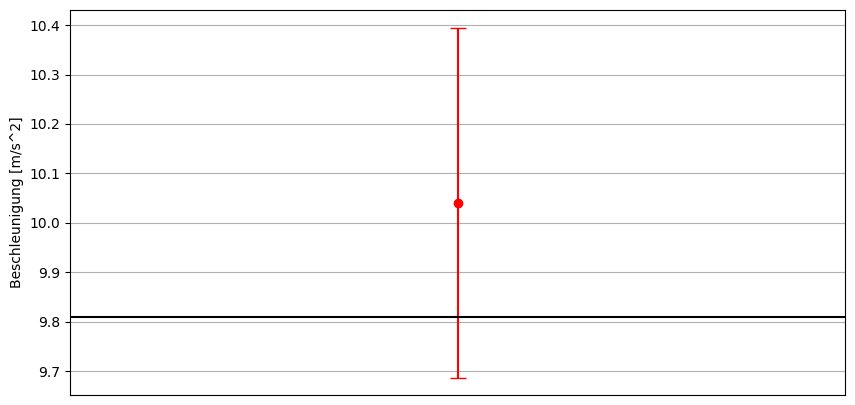

In [41]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(0, g, U_g, fmt='ro', capsize=6)
plt.axhline(9.81, color='k')  # wahrer Wert (normalerweise unbekannt)
ax.set_ylabel('Beschleunigung [m/s^2]')
ax.xaxis.set_visible(False)
ax.grid()
plt.show()